In [1]:
# DATA MINING 1
import pandas as pd
import seaborn as sns
import plotly.express as px
import numpy as np
import matplotlib.pyplot as plt
import os
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, BisectingKMeans, OPTICS, cluster_optics_dbscan
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

os.environ['LOKY_MAX_CPU_COUNT'] = '12'
from yellowbrick.cluster import SilhouetteVisualizer

# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE
#scaling, normalization
from sklearn.preprocessing import StandardScaler, MinMaxScaler

#kmeans, dbscan, hierarchical (sklearn)
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
#evaluation
from sklearn.metrics import silhouette_score
#import dataset

#distance matrix (dbscan elbow, hierarchical)
from scipy.spatial.distance import pdist, squareform

# hierarchical (scipy)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, BisectingKMeans, OPTICS, cluster_optics_dbscan
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import seaborn as sns
import plotly.express as px
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '12'

# Stile generale per i grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# CARICAMENTO DATAFRAME
df = pd.read_csv("/Users/ale/Documents/primo anno/dm1_25_26_dataset/df/DM1_game_dataset.csv")


# -----------------------------------------------
# -----------------------------------------------
# PULIZIA BASE E DEFINIZIONE GRUPPI DI COLONNE

print(f"\n----PULIZIA----")

df_cleaned = df.copy()
# Dropping delle variabili inutili
df_cleaned = df_cleaned.drop(["ComWeight", "BestPlayers", "GoodPlayers",
                              "ComMaxPlaytime", "NumComments", "ImagePath"], axis=1)

# Filtro dei valori errati = 0 non imputabili
df_cleaned = df_cleaned[df_cleaned["YearPublished"] != 0]
df_cleaned = df_cleaned[df_cleaned["MinPlayers"] != 0]
df_cleaned = df_cleaned[df_cleaned["MaxPlayers"] != 0]

# Gestione NA di Family
df_cleaned["Family"] = df_cleaned["Family"].fillna("No_Family")

# Missing values di Gameweight e ComAgeRec
df_cleaned["GameWeight"] = df_cleaned["GameWeight"].replace(0, np.nan)
df_cleaned["ComAgeRec"] = df_cleaned["ComAgeRec"].replace(np.nan, 0)


# IDEA CHIAVE: alla fine non abbiamo basi che ci permettono di rimuovere gli outliers tipo catan o Monopoli
# Però, possiamo pensare a year_published

# Colonna "Period"
condizione = [
    (df_cleaned['YearPublished'] < 1000),
    (df_cleaned['YearPublished'] >= 1000) & (
        df_cleaned['YearPublished'] < 1900),
    (df_cleaned['YearPublished'] >= 1900) & (
        df_cleaned['YearPublished'] < 2000),
    (df_cleaned['YearPublished'] >= 2000) & (
        df_cleaned['YearPublished'] < 2010),
    (df_cleaned['YearPublished'] >= 2010)
]
epoca = [
    'Pre_1000',
    '1000_1900',
    '1900_2000',
    '2000_2010',
    "2010_2021"
]
df_cleaned['Period'] = np.select(condizione, epoca, default=None)

# Colonna "Age"
df_cleaned['Age'] = 2025 - df_cleaned["YearPublished"]

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]

# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation"]


# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns
colonne_quanti = colonne_quanti.drop([
    "BGGId"] + colonne_binarie
    + colonne_rank + colonne_cat)

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist() +
    colonne_rank +
    colonne_cat 
    #colonne_binarie
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

df_cleaned['MaxPlayers']= df_cleaned['MaxPlayers'].clip(upper=99)
df_cleaned['MfgPlaytime']=df_cleaned['MfgPlaytime'].clip(upper=df_cleaned['MfgPlaytime'].quantile(0.95))
#il 0.95 di mfgplaytime era 240 quindi abbiamo usato lo stesso tempo anche per comminplaytime 
df_cleaned['ComMinPlaytime']=df_cleaned['ComMinPlaytime'].clip(upper=240)

# Creazione train_set e test_set per Data Leakage
train_set, test_set = train_test_split(
    df_cleaned, test_size=0.2, random_state=222)
train_set = train_set.copy()
test_set = test_set.copy()
print(f"\nDimensioni Train Set: {train_set.shape}")
print(f"\nDimensioni Test Set: {test_set.shape}")



# -----------------------------------------------
# -----------------------------------------------
# OUTLIERS

print(f"\n----OUTLIERS MODA----")

# Gestione missing con moda
mode_mfg_playtime = train_set["MfgPlaytime"].mode()[0]
train_set["MfgPlaytime"] = train_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)
test_set["MfgPlaytime"] = test_set["MfgPlaytime"].replace(
    0, mode_mfg_playtime)

mode_com_playtime = train_set["ComMinPlaytime"].mode()[0]
train_set["ComMinPlaytime"] = train_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)
test_set["ComMinPlaytime"] = test_set["ComMinPlaytime"].replace(
    0, mode_com_playtime)

# IMPUTAZIONE RANDOM FOREST
# Non c'è bisogno di scalare perchè gode di Invarianza Monotona

print(f"\n----OUTLIERS RANDOM FOREST----")

rf_estimator = RandomForestRegressor(
    n_estimators=22,
    random_state=222,
    n_jobs=-1
)

imputer_rf = IterativeImputer(
    estimator=rf_estimator,
    max_iter=10,
    random_state=222,
    verbose=2,               # 0 = silente, 1 = output, 2 = output dettagliato
    initial_strategy='median',
    add_indicator=False
)

df_numeric_to_impute = df_cleaned[colonne_numeriche].copy()
df_numeric_to_impute = df_numeric_to_impute.drop(["ComAgeRec"], axis=1)

imputer_rf.fit(train_set[colonne_numeriche])
imputed_array_train = imputer_rf.transform(train_set[colonne_numeriche])
imputed_array_test = imputer_rf.transform(test_set[colonne_numeriche])

train_imputed = train_set.copy()
test_imputed = test_set.copy()

train_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_train,
    columns=colonne_numeriche,
    index=train_imputed.index
)
test_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_test,
    columns=colonne_numeriche,
    index=test_imputed.index
)

# -----------------------------------------------
# -----------------------------------------------
# TRASFORMAZIONE VARIABILI (SKEWNESS)

print(f"\n----TRASFORMAZIONE----")


def fit_trasformatore(dataframe: pd.DataFrame, colonne: list, soglia: float = 1.0):

    skew_values = dataframe[colonne].skew()
    colonne_da_trasformare = skew_values[abs(skew_values) > soglia].index

    col_log = []
    col_cbrt = []

    for col in colonne_da_trasformare:
        if dataframe[col].isnull().any():
            print(f"\n  - ATTENZIONE: '{col}' contiene NaN, non dovrebbe.")
            continue

        if dataframe[col].min() < 0:
            col_cbrt.append(col)
        else:
            col_log.append(col)

    if col_log:
        print(f"\n  - Trasformazione Logaritmica identificata per: {col_log}")
    if col_cbrt:
        print(
            f"\n  - Trasformazione Radice Cubica identificata per: {col_cbrt}")

    return col_log, col_cbrt


def apply_trasformatore(dataframe: pd.DataFrame, col_log: list, col_cbrt: list):
    df_copy = dataframe.copy()

    for col in col_log:
        if col in df_copy.columns:
            df_copy[col] = np.log1p(df_copy[col])

    for col in col_cbrt:
        if col in df_copy.columns:
            df_copy[col] = np.cbrt(df_copy[col])

    return df_copy


colonne_log, colonne_cbrt = fit_trasformatore(
    train_imputed, colonne_quanti.tolist())

train_transformed = apply_trasformatore(
    train_imputed, colonne_log, colonne_cbrt)
test_transformed = apply_trasformatore(test_imputed, colonne_log, colonne_cbrt)



----PULIZIA----

Dimensioni Train Set: (17251, 42)

Dimensioni Test Set: (4313, 42)

----OUTLIERS MODA----

----OUTLIERS RANDOM FOREST----
[IterativeImputer] Completing matrix with shape (17251, 34)
[IterativeImputer] Ending imputation round 1/10, elapsed time 5.90
[IterativeImputer] Change: 1019.8181818181818, scaled tolerance: 166.497 
[IterativeImputer] Ending imputation round 2/10, elapsed time 12.11
[IterativeImputer] Change: 190.46969696969694, scaled tolerance: 166.497 
[IterativeImputer] Ending imputation round 3/10, elapsed time 18.45
[IterativeImputer] Change: 179.87878787878788, scaled tolerance: 166.497 
[IterativeImputer] Ending imputation round 4/10, elapsed time 24.92
[IterativeImputer] Change: 270.9940454545454, scaled tolerance: 166.497 
[IterativeImputer] Ending imputation round 5/10, elapsed time 31.10
[IterativeImputer] Change: 284.77272727272725, scaled tolerance: 166.497 
[IterativeImputer] Ending imputation round 6/10, elapsed time 37.36
[IterativeImputer] Chang

/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


[IterativeImputer] Ending imputation round 7/10, elapsed time 0.21
[IterativeImputer] Ending imputation round 8/10, elapsed time 0.24
[IterativeImputer] Ending imputation round 9/10, elapsed time 0.27
[IterativeImputer] Ending imputation round 10/10, elapsed time 0.30
[IterativeImputer] Completing matrix with shape (4313, 34)
[IterativeImputer] Ending imputation round 1/10, elapsed time 0.03
[IterativeImputer] Ending imputation round 2/10, elapsed time 0.06
[IterativeImputer] Ending imputation round 3/10, elapsed time 0.09
[IterativeImputer] Ending imputation round 4/10, elapsed time 0.11
[IterativeImputer] Ending imputation round 5/10, elapsed time 0.14
[IterativeImputer] Ending imputation round 6/10, elapsed time 0.17
[IterativeImputer] Ending imputation round 7/10, elapsed time 0.20
[IterativeImputer] Ending imputation round 8/10, elapsed time 0.23
[IterativeImputer] Ending imputation round 9/10, elapsed time 0.25
[IterativeImputer] Ending imputation round 10/10, elapsed time 0.28



In [ ]:
# --- Fine: Dati di esempio ---


# 1. Gestione dei valori mancanti (opzionale ma consigliato)
# Il boxplot ignora i valori NaN, ma è buona norma essere consapevoli della loro presenza.

'''
df_boxplot= df_cleaned[colonne_numeriche]
for col in df_boxplot:
    print(f"Numero di valori mancanti in:" +col " {df['MaxPlayers'].isnull().sum()}")
    sns.set_theme(style="whitegrid", palette="viridis")
    plt.figure(figsize=(10, 7))
    ax = sns.boxplot(y=col)
    ax.set_title('Distribuzione di '+ col , fontsize=16)
    ax.set_ylabel('', fontsize=12)
    ax.set_xlabel('Giochi', fontsize=12)
    plt.show()'''



# Seleziona solo le colonne numeriche dal tuo DataFrame
df_boxplot = df_cleaned[colonne_quanti]

# Imposta lo stile del grafico UNA SOLA VOLTA prima del ciclo
sns.set_theme(style="whitegrid", palette="viridis")

# Itera su ogni nome di colonna nel DataFrame df_boxplot
for col in df_boxplot.columns:
    # 1. Stampa il conteggio dei valori mancanti per la colonna CORRENTE
    # Correzione: usa una f-string pulita e accedi alla colonna corrente con df_boxplot[col]
    print(f"Numero di valori mancanti in '{col}': {df_boxplot[col].isnull().sum()}")
    
    # 2. Crea una nuova figura per ogni grafico per evitare sovrapposizioni
    plt.figure(figsize=(10, 6))
    
    # 3. Crea il boxplot passando i DATI della colonna corrente
    # Correzione: passa df_boxplot[col] a `y` invece della stringa `col`
    ax = sns.boxplot(y=df_boxplot[col])
    
    # 4. Imposta titoli ed etichette in modo dinamico
    ax.set_title(f'Distribuzione di {col}', fontsize=16)
    
    # Correzione: usa il nome della colonna come etichetta per l'asse Y
    ax.set_ylabel(col, fontsize=12)
    
    # L'etichetta dell'asse X può essere generica o rimossa se non aggiunge informazioni
    ax.set_xlabel('Distribuzione', fontsize=12)
    
    # 5. Mostra il grafico per la colonna corrente prima di passare alla successiva
    plt.show()


In [28]:
from pyclustering.cluster import xmeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import NearestNeighbors
from mpl_toolkits.mplot3d import Axes3D


plt.rcParams['figure.figsize'] = (6, 4)

# Dataset_cluster
train_cluster = train_imputed.copy()
test_cluster = test_imputed.copy()
colonne_cluster = ["MinPlayers", "GameWeight", "ComAgeRec",
                   "NumWant", "NumUserRatings", "NumImplementations"]
train_cluster = train_cluster[colonne_cluster]
test_cluster = test_cluster[colonne_cluster]
X = train_cluster
y = np.array(train_imputed['Rating'])

scaler = MinMaxScaler()
X_minmax = scaler.fit_transform(X)
standard_scaler = StandardScaler()
X_standard = standard_scaler.fit_transform(X)

# PCA
features = train_cluster.select_dtypes(include=[np.number])
features_scaled = scaler.fit_transform(features)
pca = PCA(n_components=6, random_state=222)
principal_components = pca.fit_transform(features_scaled)
pca_df = pd.DataFrame(data=principal_components,
                      columns=['PC1', 'PC2', "PC3", "PC4", "PC5", "PC6"])

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance)

print("\n--- Varianza Spiegata ---")
print(
    f"Varianza spiegata da PC1: {explained_variance[0]:.4f} ({explained_variance[0]*100:.2f}%)")
print(
    f"Varianza spiegata da PC2: {explained_variance[1]:.4f} ({explained_variance[1]*100:.2f}%)")
print(
    f"Varianza spiegata da PC3: {explained_variance[2]:.4f} ({explained_variance[2]*100:.2f}%)")
print(
    f"Varianza spiegata da PC4: {explained_variance[3]:.4f} ({explained_variance[3]*100:.2f}%)")

print(
    f"Varianza spiegata da PC5: {explained_variance[4]:.4f} ({explained_variance[4]*100:.2f}%)")

print(
    f"Varianza spiegata da PC6: {explained_variance[5]:.4f} ({explained_variance[5]*100:.2f}%)")

print(
    f"Varianza Totale Spiegata (6 componenti): {total_explained_variance:.4f} ({total_explained_variance*100:.2f}%)")



--- Varianza Spiegata ---
Varianza spiegata da PC1: 0.6480 (64.80%)
Varianza spiegata da PC2: 0.2550 (25.50%)
Varianza spiegata da PC3: 0.0493 (4.93%)
Varianza spiegata da PC4: 0.0344 (3.44%)
Varianza spiegata da PC5: 0.0097 (0.97%)
Varianza spiegata da PC6: 0.0035 (0.35%)
Varianza Totale Spiegata (6 componenti): 1.0000 (100.00%)


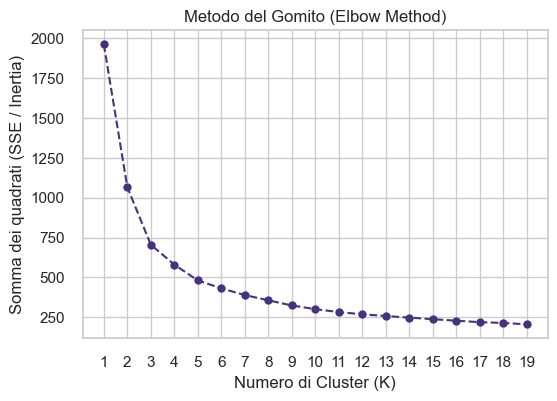

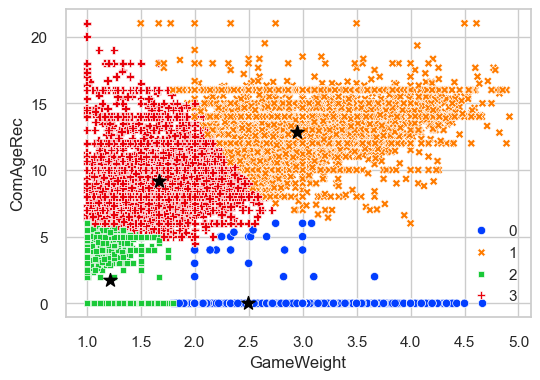

In [29]:
# K_Means
sse = []
k_range = range(1, 20)

for k in k_range:

    kmeans_model = KMeans(n_clusters=k,
                          n_init=10,
                          max_iter=100,
                          random_state=222)

    kmeans_model.fit(X_minmax)

    sse.append(kmeans_model.inertia_)

plt.plot(k_range, sse, marker='o', linestyle='--')
plt.xlabel("Numero di Cluster (K)")
plt.ylabel("Somma dei quadrati (SSE / Inertia)")
plt.title("Metodo del Gomito (Elbow Method)")
plt.xticks(k_range)
plt.grid(True)
plt.show()

kmeans = KMeans(n_clusters=4, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

centers = kmeans.cluster_centers_
centers_unscaled = scaler.inverse_transform(centers)

sns.scatterplot(data=train_cluster,
                x="GameWeight",
                y="ComAgeRec",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.scatter(
    centers_unscaled[:, 1],
    centers_unscaled[:, 2],
    color="black", marker="*", s=100
)
plt.show()



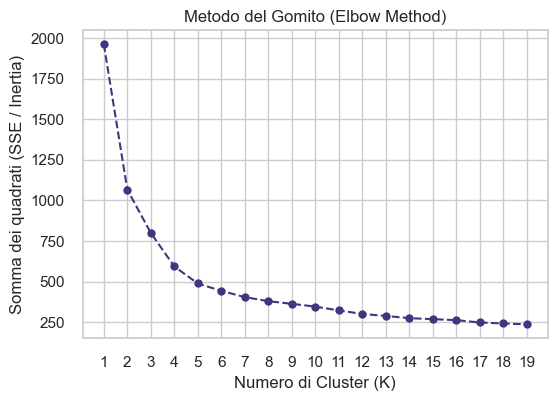

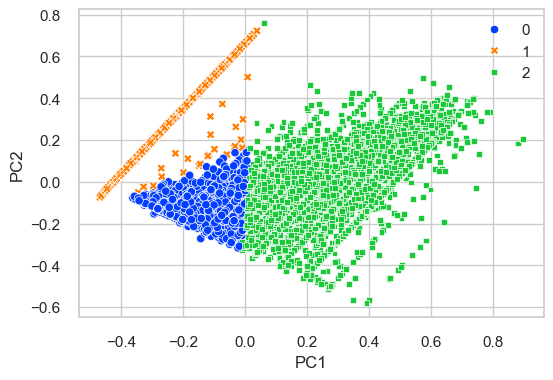

In [30]:
# Bisecting K_Means
sse = []
k_range = range(1, 20)

for k in k_range:

    bkmeans_model = BisectingKMeans(n_clusters=k,
                                    n_init=10,
                                    max_iter=100,
                                    random_state=222)

    bkmeans_model.fit(X_minmax)

    sse.append(bkmeans_model.inertia_)

plt.plot(k_range, sse, marker='o', linestyle='--')
plt.xlabel("Numero di Cluster (K)")
plt.ylabel("Somma dei quadrati (SSE / Inertia)")
plt.title("Metodo del Gomito (Elbow Method)")
plt.xticks(k_range)
plt.grid(True)
plt.show()

bkmeans = BisectingKMeans(n_clusters=3, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=bkmeans.labels_,
                style=bkmeans.labels_,
                palette="bright")
plt.show()



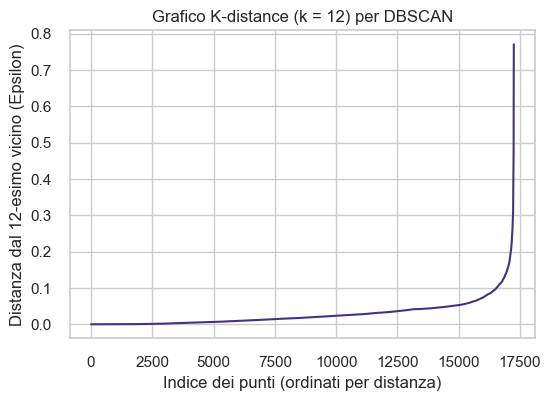

In [31]:

# DBScan

D = X_minmax.shape[1]
MinPts = 2 * D
k = MinPts

nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_minmax)
distances, indices = nn.kneighbors(X_minmax)

k_distances = distances[:, k-1]
k_distances_sorted = np.sort(k_distances)
plt.plot(range(len(k_distances_sorted)), k_distances_sorted)
plt.title(f'Grafico K-distance (k = {k}) per DBSCAN')
plt.xlabel('Indice dei punti (ordinati per distanza)')
plt.ylabel(f'Distanza dal {k}-esimo vicino (Epsilon)')
plt.grid(True)
plt.show()


dbscan = DBSCAN(eps=0.1, min_samples=100)
dbscan.fit(X_minmax)

plot_df = pca_df.copy()
plot_df['cluster'] = dbscan.labels_.astype(str)

fig = px.scatter_3d(
    plot_df,
    x='PC1',
    y='PC2',
    z='PC3',
    color='cluster',  # Colora automaticamente in base alla colonna 'cluster'
    title='DBSCAN Clustering 3D (Interattivo)',

    # Mappa manuale per il rumore: assegna 'darkgrey' all'etichetta '-1'
    # Plotly assegnerà automaticamente colori vivaci agli altri cluster
    color_discrete_map={'-1': 'darkgrey'}
)

fig.update_traces(
    marker=dict(size=3, opacity=0.7),  # Imposta dimensione e opacità
    selector=dict(mode='markers')
)

fig.show()



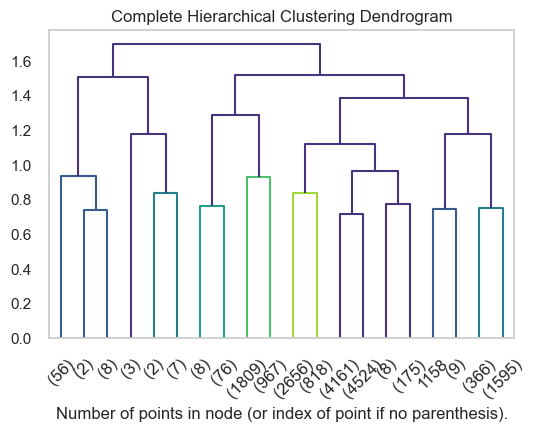

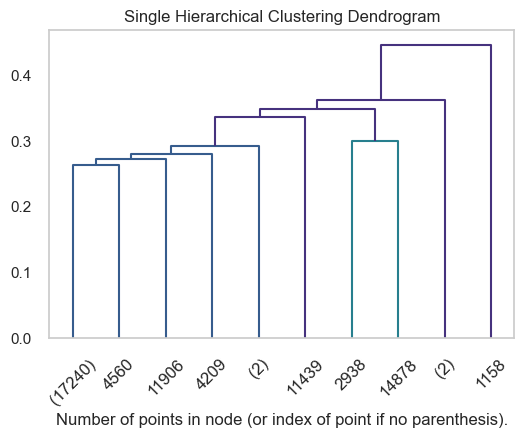

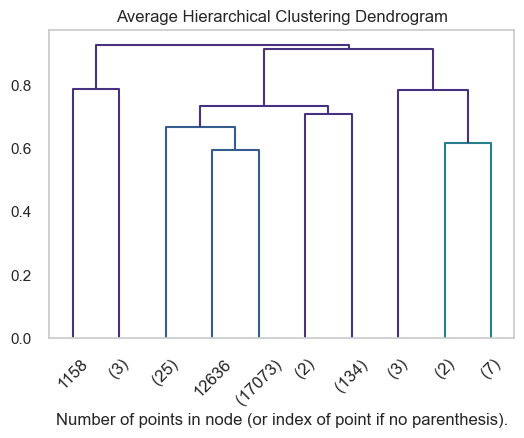

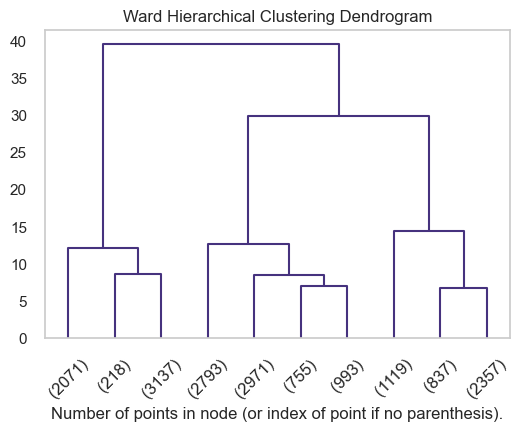

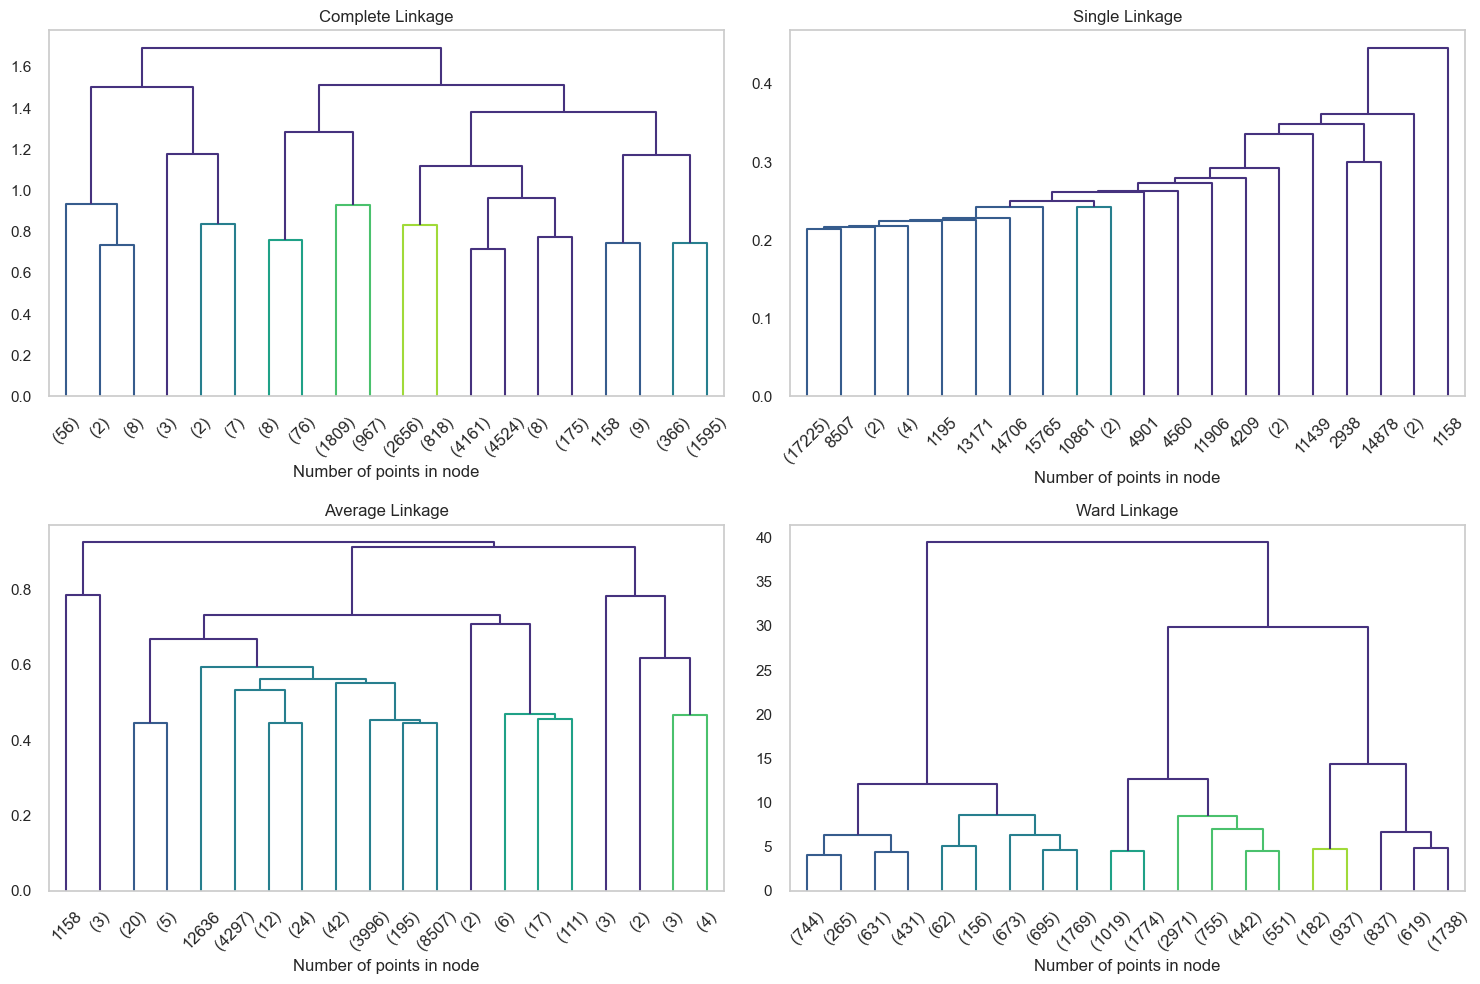

In [54]:
# Gerarchico

def get_linkage_matrix(model):
    # Create linkage matrix

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    return linkage_matrix


def plot_dendrogram(model, **kwargs):
    linkage_matrix = get_linkage_matrix(model)
    dendrogram(linkage_matrix, **kwargs)


#Complete
ierarchico1 = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                # giocare con tipo distanza e tipo di link
                                metric='euclidean', linkage='complete')
model_complete = ierarchico1.fit(X_minmax)

uno = get_linkage_matrix(model_complete)
labels = fcluster(uno, t=0.7, criterion='distance')  # con t scegliamo dove "tagliare" il grafico per prendere i clusters
# usare labels per grafico 3d gerarchico

plt.title("Complete Hierarchical Clustering Dendrogram")
plot_dendrogram(model_complete, truncate_mode='lastp', p=20, color_threshold=1)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.xticks(rotation=45) # Ruota le etichette se sono lunghe
plt.grid()
plt.show()

#Single
ierarchico2 = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                 # giocare con tipo distanza e tipo di link
                                 metric='euclidean', linkage='single')
model_single = ierarchico2.fit(X_minmax)

due = get_linkage_matrix(model_single)
labels = fcluster(due, t=0.7, criterion='distance')  # con t scegliamo dove "tagliare" il grafico per prendere i clusters
# usare labels per grafico 3d gerarchico

plt.title("Single Hierarchical Clustering Dendrogram")
plot_dendrogram(model_single, truncate_mode='lastp', p=10, color_threshold=0.31)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.xticks(rotation=45) # Ruota le etichette se sono lunghe
plt.grid()
plt.show()

#Average
ierarchico3 = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                 # giocare con tipo distanza e tipo di link
                                 metric='euclidean', linkage='average')
model_average = ierarchico3.fit(X_minmax)

tre = get_linkage_matrix(model_average)
labels = fcluster(tre, t=0.7, criterion='distance')  # con t scegliamo dove "tagliare" il grafico per prendere i clusters
# usare labels per grafico 3d gerarchico

plt.title("Average Hierarchical Clustering Dendrogram")
plot_dendrogram(model_average, truncate_mode='lastp', p=10, color_threshold=0.7)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.xticks(rotation=45) # Ruota le etichette se sono lunghe
plt.grid()
plt.show()

#Ward
ierarchico4 = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                 # giocare con tipo distanza e tipo di link
                                 metric='euclidean', linkage='ward')
model_ward = ierarchico4.fit(X_minmax)

quattro = get_linkage_matrix(model_ward)
labels = fcluster(quattro, t=0.7, criterion='distance')  # con t scegliamo dove "tagliare" il grafico per prendere i clusters
# usare labels per grafico 3d gerarchico

plt.title("Ward Hierarchical Clustering Dendrogram")
plot_dendrogram(model_ward, truncate_mode='lastp', p=10, color_threshold=0.20)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.xticks(rotation=45) # Ruota le etichette se sono lunghe
plt.grid()
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(15, 10))
axs[0, 0].set_title("Complete Linkage")
dendrogram(uno, truncate_mode='lastp', p=20, color_threshold=1, ax=axs[0, 0])
axs[0, 0].set_xlabel("Number of points in node")
axs[0, 0].grid()
axs[0,0].tick_params(axis='x', rotation=45)
axs[0, 1].set_title("Single Linkage")
dendrogram(due, truncate_mode='lastp', p=20, color_threshold=0.25, ax=axs[0, 1])
axs[0, 1].set_xlabel("Number of points in node")
axs[0, 1].grid()
axs[0,1].tick_params(axis='x', rotation=45)
axs[1, 0].set_title("Average Linkage")
dendrogram(tre, truncate_mode='lastp', p=20, color_threshold=0.6, ax=axs[1, 0])
axs[1, 0].set_xlabel("Number of points in node")
axs[1, 0].grid()
axs[1,0].tick_params(axis='x', rotation=45)
axs[1, 1].set_title("Ward Linkage")
dendrogram(quattro, truncate_mode='lastp', p=20, color_threshold=10, ax=axs[1, 1])
axs[1, 1].set_xlabel("Number of points in node")
axs[1, 1].grid()
axs[1,1].tick_params(axis='x', rotation=45) # Ruota le etichette se sono lunghe
plt.tight_layout()
plt.show()

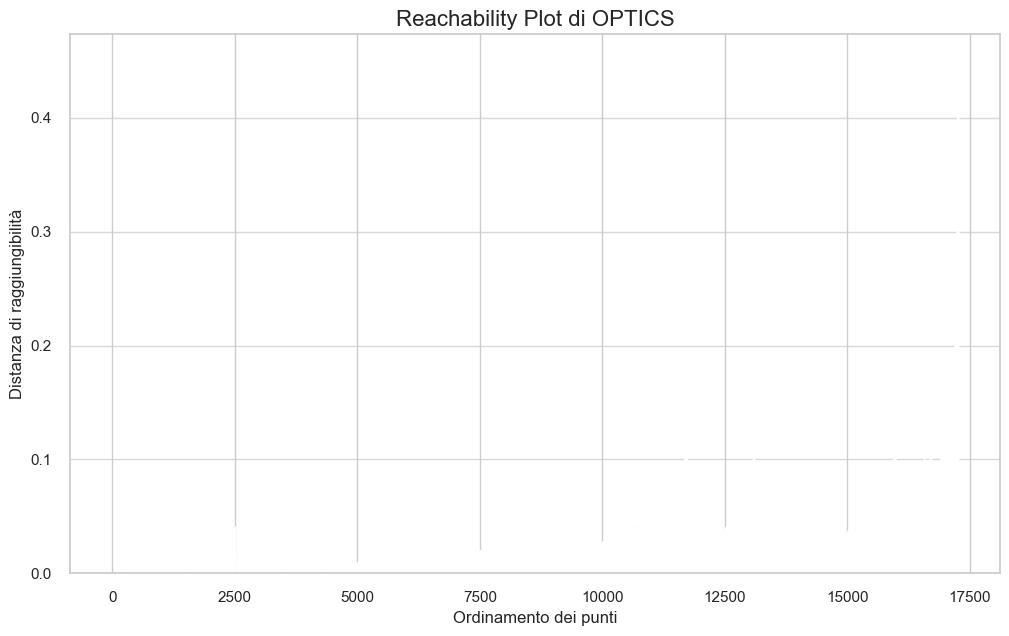

Numero di cluster stimati: 1
Numero di punti di rumore stimati: 15892


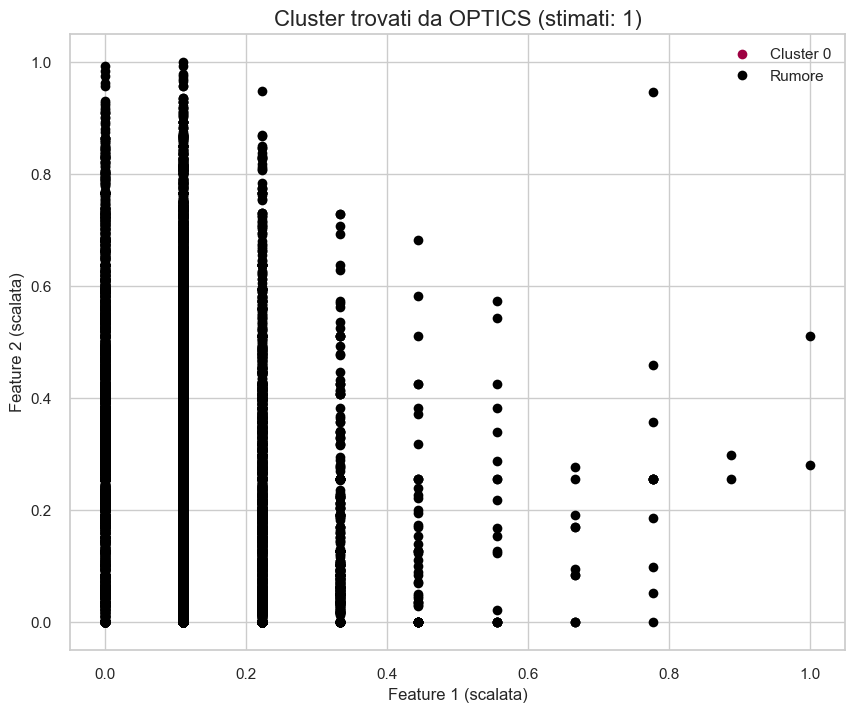

'\n# --- INIZIO DEBUG ---\nprint(f"Forma del dataset (campioni, feature): {X_minmax.shape}")\nprint(f"Valore di min_samples usato: {optics_model.min_samples}")\n\n# Controlla l\'array di raggiungibilità. Se è vuoto, il problema è qui.\nreachability_array = optics_model.reachability_[optics_model.ordering_]\n\n# Controlla se tutti i valori sono infiniti\nif np.all(np.isinf(reachability_array)):\n    print("\nERRORE RILEVATO: Tutte le distanze di raggiungibilità sono infinite!")\n    print("Questo significa che \'min_samples\' è quasi certamente troppo alto per la densità del tuo dataset.")\nelse:\n    print("\nL\'array di raggiungibilità contiene valori finiti. Il problema potrebbe essere altrove.")\n\n# Controlla anche le etichette. Se sono tutte -1, è un\'altra conferma.\nlabels = optics_model.labels_\nif np.all(labels == -1):\n    print("Tutti i punti sono stati classificati come rumore (-1). Questa è un\'ulteriore prova che \'min_samples\' è troppo alto.")\n# --- FINE DEBUG ---'

In [69]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import OPTICS
from sklearn.preprocessing import StandardScaler
'''#optics
print("\n----CLUSTERING (Optics)----")

optics = OPTICS(min_samples=20, max_eps=np.inf, min_cluster_size=10)
optics.fit(X_minmax)

sns.scatterplot(pca_df,
                x="PC1",
                y="PC2",
                hue=dbscan.labels_,
                style=optics.labels_,
                palette="bright")
plt.show()'''

optics_model = OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.05)

# Eseguiamo il fit sui dati scalati
optics_model.fit(X_minmax)


# --- 3. ANALISI E VISUALIZZAZIONE DEI RISULTATI ---

# a) Il Reachability Plot (il risultato principale di OPTICS)
# Questo grafico è la chiave per capire la struttura dei cluster.
# Le "valli" nel grafico rappresentano i cluster. Più profonda la valle, più denso il cluster.
# I "picchi" rappresentano le separazioni tra i cluster.

reachability = optics_model.reachability_[optics_model.ordering_]
ordering = optics_model.ordering_

plt.figure(figsize=(12, 7))
ax1 = plt.gca()

# Disegna il reachability plot
colors = ['c.', 'b.', 'r.', 'g.', 'm.'] # Colori per i cluster
for klass, color in zip(range(0, 5), colors):
    Xk = X_minmax[optics_model.labels_ == klass]
    # Questo è solo per colorare il grafico, non è essenziale per la visualizzazione
    # Se non vuoi colorare, puoi semplicemente fare plt.plot(reachability)
    
# Disegna le barre di raggiungibilità
space = np.arange(len(X_minmax))
ax1.bar(space, reachability, width=1.0, color='black', edgecolor=None)

ax1.set_ylabel('Distanza di raggiungibilità')
ax1.set_xlabel('Ordinamento dei punti')
ax1.set_title('Reachability Plot di OPTICS', fontsize=16)
plt.grid(axis='y', alpha=0.75)
plt.show()


# b) Visualizzazione dei cluster trovati sui dati originali
# I label -1 indicano i punti considerati "rumore" (noise).

labels = optics_model.labels_
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f"Numero di cluster stimati: {n_clusters_}")
print(f"Numero di punti di rumore stimati: {n_noise_}")

plt.figure(figsize=(10, 8))
# Disegna i punti, colorandoli in base al cluster assegnato
# I punti di rumore (-1) vengono disegnati in nero.
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Colore nero per il rumore
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)
    
    # Punti del cluster
    xy = X_minmax[class_member_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col), markeredgecolor='k', markersize=7, label=f'Cluster {k}' if k != -1 else 'Rumore')

plt.title(f'Cluster trovati da OPTICS (stimati: {n_clusters_})', fontsize=16)
plt.xlabel("Feature 1 (scalata)")
plt.ylabel("Feature 2 (scalata)")
plt.legend()
plt.grid(True)
plt.show()

# Esegui il fit come prima
optics_model = OPTICS(min_samples=50) # Esempio con un valore potenzialmente troppo alto
optics_model.fit(X_minmax)
'''
# --- INIZIO DEBUG ---
print(f"Forma del dataset (campioni, feature): {X_minmax.shape}")
print(f"Valore di min_samples usato: {optics_model.min_samples}")

# Controlla l'array di raggiungibilità. Se è vuoto, il problema è qui.
reachability_array = optics_model.reachability_[optics_model.ordering_]

# Controlla se tutti i valori sono infiniti
if np.all(np.isinf(reachability_array)):
    print("\nERRORE RILEVATO: Tutte le distanze di raggiungibilità sono infinite!")
    print("Questo significa che 'min_samples' è quasi certamente troppo alto per la densità del tuo dataset.")
else:
    print("\nL'array di raggiungibilità contiene valori finiti. Il problema potrebbe essere altrove.")

# Controlla anche le etichette. Se sono tutte -1, è un'altra conferma.
labels = optics_model.labels_
if np.all(labels == -1):
    print("Tutti i punti sono stati classificati come rumore (-1). Questa è un'ulteriore prova che 'min_samples' è troppo alto.")
# --- FINE DEBUG ---'''


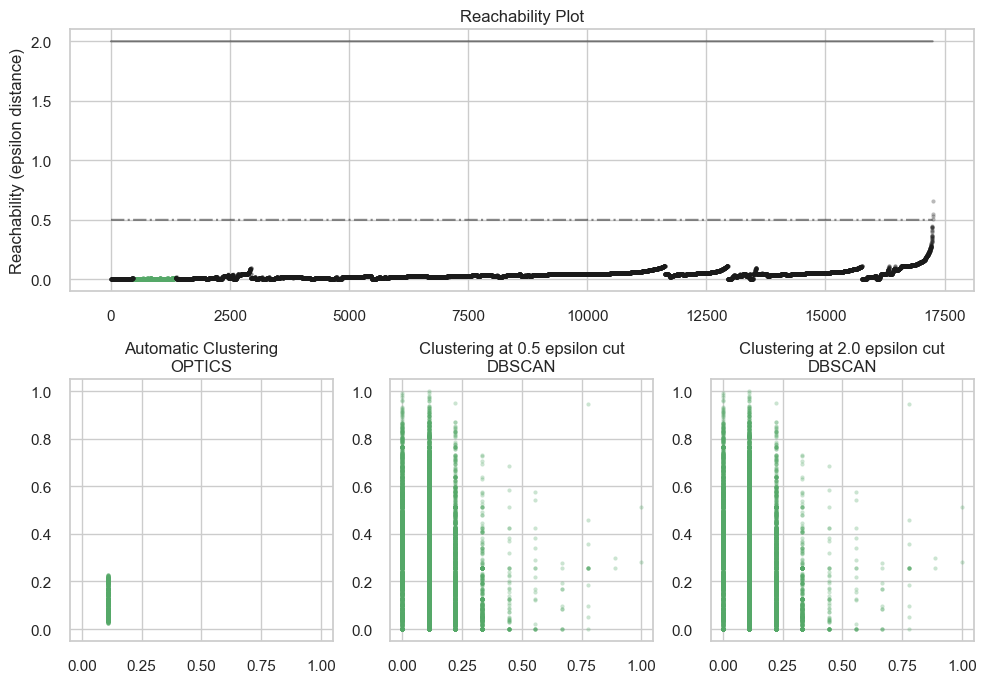

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_70126/1267379760.py:157: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_70126/1267379760.py:176: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_70126/1267379760.py:189: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_70126/1267379760.

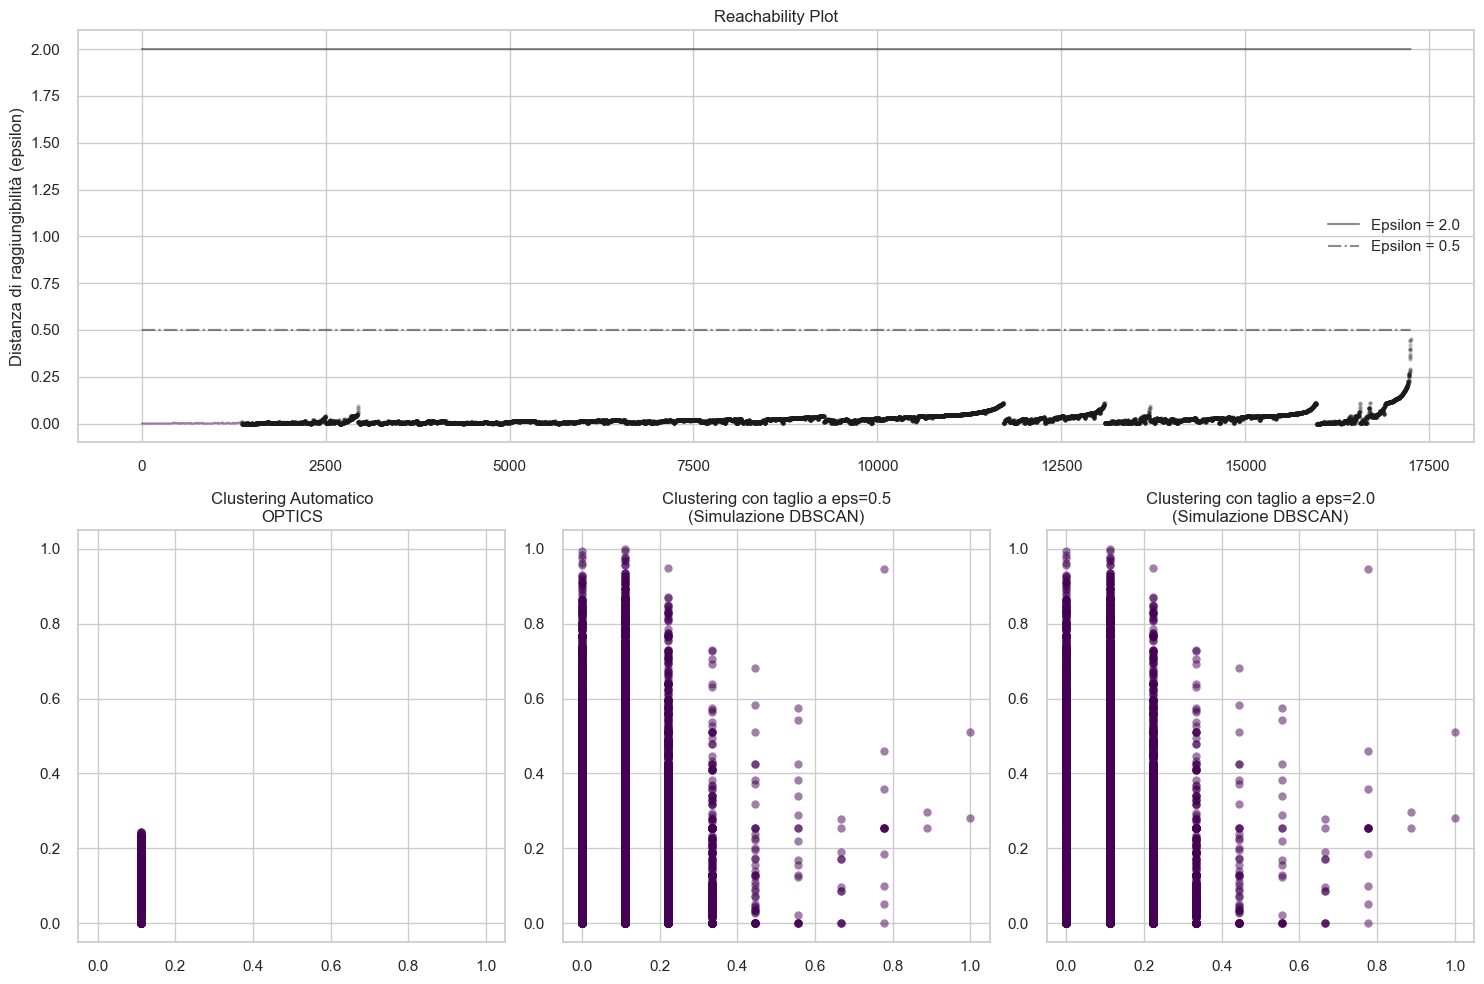

In [77]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import OPTICS, cluster_optics_dbscan

# Generate sample data

np.random.seed(0)
n_points_per_cluster = 250

C1 = [-5, -2] + 0.8 * np.random.randn(n_points_per_cluster, 2)
C2 = [4, -1] + 0.1 * np.random.randn(n_points_per_cluster, 2)
C3 = [1, -2] + 0.2 * np.random.randn(n_points_per_cluster, 2)
C4 = [-2, 3] + 0.3 * np.random.randn(n_points_per_cluster, 2)
C5 = [3, -2] + 1.6 * np.random.randn(n_points_per_cluster, 2)
C6 = [5, 6] + 2 * np.random.randn(n_points_per_cluster, 2)
X = np.vstack((C1, C2, C3, C4, C5, C6))

clust = OPTICS(min_samples=50, xi=0.05, min_cluster_size=0.05)

# Run the fit
clust.fit(X_minmax)

labels_050 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=0.5,
)
labels_200 = cluster_optics_dbscan(
    reachability=clust.reachability_,
    core_distances=clust.core_distances_,
    ordering=clust.ordering_,
    eps=2,
)

space = np.arange(len(X_minmax))
reachability = clust.reachability_[clust.ordering_]
labels = clust.labels_[clust.ordering_]

plt.figure(figsize=(10, 7))
G = gridspec.GridSpec(2, 3)
ax1 = plt.subplot(G[0, :])
ax2 = plt.subplot(G[1, 0])
ax3 = plt.subplot(G[1, 1])
ax4 = plt.subplot(G[1, 2])

# Reachability plot
colors = ["g.", "r.", "b.", "y.", "c."]
for klass, color in enumerate(colors):
    Xk = space[labels == klass]
    Rk = reachability[labels == klass]
    ax1.plot(Xk, Rk, color, alpha=0.3)
ax1.plot(space[labels == -1], reachability[labels == -1], "k.", alpha=0.3)
ax1.plot(space, np.full_like(space, 2.0, dtype=float), "k-", alpha=0.5)
ax1.plot(space, np.full_like(space, 0.5, dtype=float), "k-.", alpha=0.5)
ax1.set_ylabel("Reachability (epsilon distance)")
ax1.set_title("Reachability Plot")

# OPTICS
colors = ["g.", "r.", "b.", "y.", "c."]
for klass, color in enumerate(colors):
    Xk = X_minmax[clust.labels_ == klass]
    ax2.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
ax2.plot(X_minmax[clust.labels_ == -1, 0], X_minmax[clust.labels_ == -1, 1], "k+", alpha=0.1)
ax2.set_title("Automatic Clustering\nOPTICS")

# DBSCAN at 0.5
colors = ["g.", "r.", "b.", "c."]
for klass, color in enumerate(colors):
    Xk = X_minmax[labels_050 == klass]
    ax3.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
ax3.plot(X_minmax[labels_050 == -1, 0], X_minmax[labels_050 == -1, 1], "k+", alpha=0.1)
ax3.set_title("Clustering at 0.5 epsilon cut\nDBSCAN")

# DBSCAN at 2.
colors = ["g.", "m.", "y.", "c."]
for klass, color in enumerate(colors):
    Xk = X_minmax[labels_200 == klass]
    ax4.plot(Xk[:, 0], Xk[:, 1], color, alpha=0.3)
ax4.plot(X_minmax[labels_200 == -1, 0], X_minmax[labels_200 == -1, 1], "k+", alpha=0.1)
ax4.set_title("Clustering at 2.0 epsilon cut\nDBSCAN")

plt.tight_layout()
plt.show()




# Import delle librerie necessarie
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import OPTICS, cluster_optics_dbscan

# --- 1. DATI E MODELLO FORNITI DA TE ---
# Assumiamo che queste variabili siano già state definite e addestrate nel tuo script:
# X_minmax: i tuoi dati, scalati e pronti per l'analisi.
# optics_model: il tuo modello OPTICS già addestrato su X_minmax.
#
# Esempio di come potresti averle create (NON ESEGUIRE SE LE HAI GIA'):
# from sklearn.preprocessing import MinMaxScaler
# # ... caricamento del tuo DataFrame df ...
# scaler = MinMaxScaler()
# X_minmax = scaler.fit_transform(df)
# optics_model = OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.05)
# optics_model.fit(X_minmax)
# --------------------------------------------------------------------


# --- 2. ESTRAZIONE DEI CLUSTER CON DIVERSI EPSILON ---
# Questa parte del codice originale è molto utile: usa i risultati del tuo
# modello OPTICS per simulare come si comporterebbe DBSCAN con due diversi
# valori di 'eps' (la soglia di distanza).
# Utilizziamo gli attributi del tuo 'optics_model' addestrato.

labels_050 = cluster_optics_dbscan(
    reachability=optics_model.reachability_,
    core_distances=optics_model.core_distances_,
    ordering=optics_model.ordering_,
    eps=0.5,  # Puoi modificare questo valore per testare diverse soglie
)
labels_200 = cluster_optics_dbscan(
    reachability=optics_model.reachability_,
    core_distances=optics_model.core_distances_,
    ordering=optics_model.ordering_,
    eps=2.0,   # Puoi modificare questo valore per testare diverse soglie
)


# --- 3. PREPARAZIONE PER IL PLOTTING ---
# Adattiamo le variabili per il plotting usando i tuoi dati e il tuo modello.

# 'space' rappresenta l'asse x del reachability plot. La sua dimensione deve corrispondere ai tuoi dati.
space = np.arange(len(X_minmax)) 
# Estraiamo i risultati ordinati dal tuo modello per un plotting corretto.
reachability = optics_model.reachability_[optics_model.ordering_]
labels = optics_model.labels_[optics_model.ordering_]


# --- 4. CREAZIONE DEI GRAFICI (Struttura originale mantenuta) ---

plt.figure(figsize=(15, 10)) # Aumentata leggermente la dimensione per una migliore leggibilità
G = gridspec.GridSpec(2, 3)
ax1 = plt.subplot(G[0, :])
ax2 = plt.subplot(G[1, 0])
ax3 = plt.subplot(G[1, 1])
ax4 = plt.subplot(G[1, 2])

# Plot 1: Reachability plot
# Miglioramento: uso un set di colori dinamico per evitare errori se ci sono più cluster dei colori predefiniti.
unique_labels_plot = np.unique(labels)
colors_plot = plt.cm.get_cmap('viridis', len(unique_labels_plot))

for klass in unique_labels_plot:
    if klass == -1: continue # Gestiamo il rumore separatamente
    Xk = space[labels == klass]
    Rk = reachability[labels == klass]
    ax1.plot(Xk, Rk, color=colors_plot(klass), alpha=0.5)
# Plot del rumore
ax1.plot(space[labels == -1], reachability[labels == -1], "k.", alpha=0.3)
# Linee di taglio per DBSCAN
ax1.plot(space, np.full_like(space, 2.0, dtype=float), "k-", alpha=0.5, label='Epsilon = 2.0')
ax1.plot(space, np.full_like(space, 0.5, dtype=float), "k-.", alpha=0.5, label='Epsilon = 0.5')
ax1.set_ylabel("Distanza di raggiungibilità (epsilon)")
ax1.set_title("Reachability Plot")
ax1.legend()

# Plot 2: Risultato del clustering automatico di OPTICS
# Miglioramento: uso un set di colori dinamico
unique_labels_model = np.unique(optics_model.labels_)
colors_model = plt.cm.get_cmap('viridis', len(unique_labels_model))

for klass in unique_labels_model:
    if klass == -1: continue
    # Usiamo i tuoi dati X_minmax
    Xk = X_minmax[optics_model.labels_ == klass]
    ax2.plot(Xk[:, 0], Xk[:, 1], 'o', color=colors_model(klass), alpha=0.5)
# Plot del rumore
ax2.plot(X_minmax[optics_model.labels_ == -1, 0], X_minmax[optics_model.labels_ == -1, 1], "k+", alpha=0.1)
ax2.set_title("Clustering Automatico\nOPTICS")

# Plot 3: Clustering con taglio a epsilon = 0.5
unique_labels_050 = np.unique(labels_050)
colors_050 = plt.cm.get_cmap('viridis', len(unique_labels_050))
for klass in unique_labels_050:
    if klass == -1: continue
    Xk = X_minmax[labels_050 == klass]
    ax3.plot(Xk[:, 0], Xk[:, 1], 'o', color=colors_050(klass), alpha=0.5)
ax3.plot(X_minmax[labels_050 == -1, 0], X_minmax[labels_050 == -1, 1], "k+", alpha=0.1)
ax3.set_title("Clustering con taglio a eps=0.5\n(Simulazione DBSCAN)")

# Plot 4: Clustering con taglio a epsilon = 2.0
unique_labels_200 = np.unique(labels_200)
colors_200 = plt.cm.get_cmap('viridis', len(unique_labels_200))
for klass in unique_labels_200:
    if klass == -1: continue
    Xk = X_minmax[labels_200 == klass]
    ax4.plot(Xk[:, 0], Xk[:, 1], 'o', color=colors_200(klass), alpha=0.5)
ax4.plot(X_minmax[labels_200 == -1, 0], X_minmax[labels_200 == -1, 1], "k+", alpha=0.1)
ax4.set_title("Clustering con taglio a eps=2.0\n(Simulazione DBSCAN)")

plt.tight_layout()
plt.show()




Conteggio dei punti per ogni cluster:
cluster
0    9611
1    7640
Name: count, dtype: int64
------------------------------


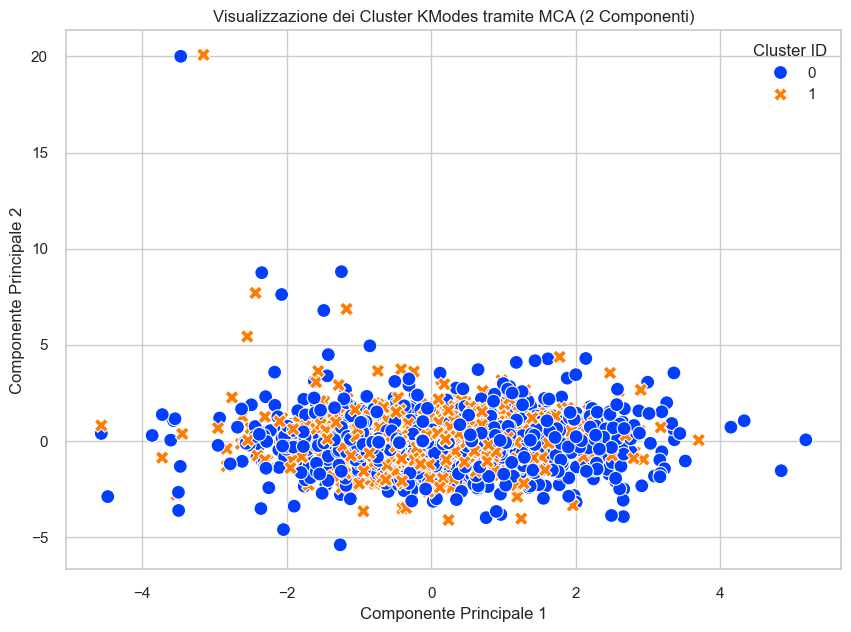

"\n\nfig = px.scatter_3d(plot_data,\n    x='Componente 1',\n    y='Componente 2',\n    z='Componente 3',\n    color='cluster',  # Colora automaticamente in base alla colonna 'cluster'\n    title='DBSCAN Clustering 3D (Interattivo)',\n\n    # Mappa manuale per il rumore: assegna 'darkgrey' all'etichetta '-1'\n    # Plotly assegnerà automaticamente colori vivaci agli altri cluster\n    color_discrete_map={'-1': 'darkgrey'}\n)\n\nfig.update_traces(\n    marker=dict(size=3, opacity=0.7),  # Imposta dimensione e opacità\n    selector=dict(mode='markers')\n)\n"

In [33]:
# K-mode CE NE HO MESSO ANCHE 3 DA SISTEMARE
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from kmodes.kmodes import KModes
import prince

# Seleziona le colonne per il clustering.
# È meglio lavorare direttamente con il DataFrame per MCA.
colonne_cluster2 = ["Family", "Rating", "Period"]
train_cluster2_df = train_imputed[colonne_cluster2]

# --- 2. Esecuzione del Clustering con KModes ---
# Inizializza il modello KModes
km = KModes(n_clusters=2, init='Huang', n_init=5, verbose=0, random_state=42)

# Addestra il modello e ottieni le etichette dei cluster
clusters = km.fit_predict(train_cluster2_df)

# --- 3. Correzione dell'assegnazione e verifica ---
# Aggiungi i risultati del clustering come nuova colonna al DataFrame originale
train_imputed['cluster'] = clusters

# Stampa il conteggio dei membri per ogni cluster (questo è il modo corretto)
print("Conteggio dei punti per ogni cluster:")
print(train_imputed['cluster'].value_counts())
print("-" * 30)

# --- 4. Adattamento del Grafico: Riduzione Dimensionale con MCA ---
# KModes lavora con dati categorici, quindi usiamo MCA per visualizzarli in 2D.
mca = prince.MCA(
    n_components=2, # Vogliamo ridurre a 2 dimensioni (x e y)
    n_iter=3,
    random_state=42
)

# Adatta e trasforma i dati
coordinates = mca.fit_transform(train_cluster2_df)
coordinates.columns = ['Componente 1', 'Componente 2']

# Unisci le coordinate 2D con i risultati del clustering
plot_data = pd.concat([coordinates, train_imputed['cluster']], axis=1)


# --- 5. Creazione dello Scatterplot ---
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_data,
    x="Componente 1",
    y="Componente 2",
    hue="cluster",          # Colora i punti in base al cluster di appartenenza
    style="cluster",        # Usa simboli diversi per ogni cluster
    palette="bright",       # Palette di colori vivace
    s=100                   # Aumenta la dimensione dei punti per una migliore visibilità
)

plt.title('Visualizzazione dei Cluster KModes tramite MCA (2 Componenti)')
plt.xlabel('Componente Principale 1')
plt.ylabel('Componente Principale 2')
plt.legend(title='Cluster ID')
plt.grid(True)
plt.show()
'''

fig = px.scatter_3d(plot_data,
    x='Componente 1',
    y='Componente 2',
    z='Componente 3',
    color='cluster',  # Colora automaticamente in base alla colonna 'cluster'
    title='DBSCAN Clustering 3D (Interattivo)',

    # Mappa manuale per il rumore: assegna 'darkgrey' all'etichetta '-1'
    # Plotly assegnerà automaticamente colori vivaci agli altri cluster
    color_discrete_map={'-1': 'darkgrey'}
)

fig.update_traces(
    marker=dict(size=3, opacity=0.7),  # Imposta dimensione e opacità
    selector=dict(mode='markers')
)
'''
#fig.show()

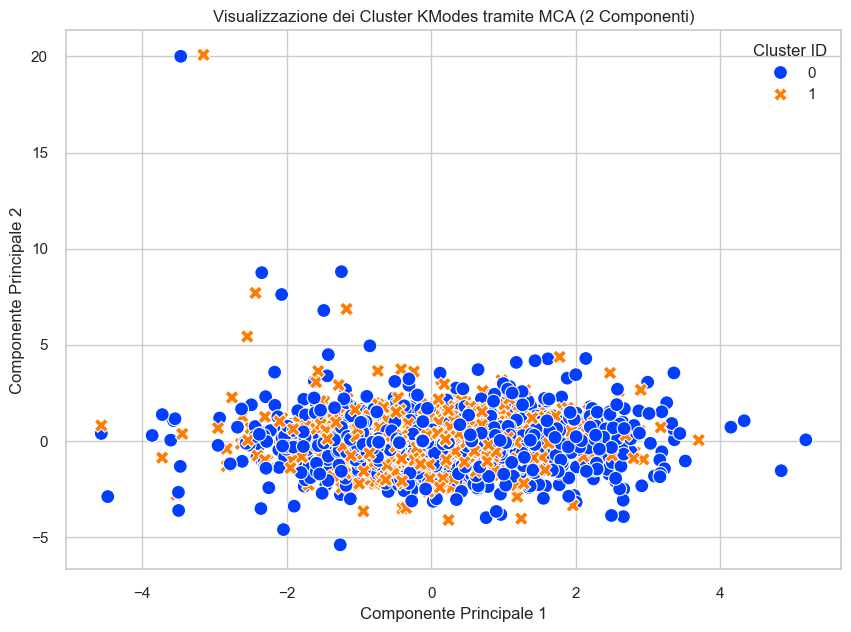

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from kmodes.kmodes import KModes

# Eseguiamo KModes
km = KModes(n_clusters=3, init='Huang', n_init=5, random_state=42)
train_imputed['cluster'] = km.fit_predict(train_cluster2_df)

# --- 2. Visualizzazione con Grafici a Barre ---
# Itera su ogni colonna usata per il clustering
'''for colonna in colonne_cluster2:
    plt.figure(figsize=(10, 6))
    sns.countplot(
        x=colonna,              # La variabile categorica sull'asse x
        hue='cluster',          # Colora le barre in base al cluster
        data=train_imputed,
        palette='bright'
    )
    plt.title(f'Distribuzione della Variabile "{colonna}" per Cluster', fontsize=14)
    plt.ylabel('Conteggio')
    plt.xlabel(colonna)
    plt.legend(title='Cluster ID')
    plt.xticks(rotation=45) # Ruota le etichette se sono lunghe
    plt.show()'''

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_data,
    x="Componente 1",
    y="Componente 2",
    hue="cluster",          # Colora i punti in base al cluster di appartenenza
    style="cluster",        # Usa simboli diversi per ogni cluster
    palette="bright",       # Palette di colori vivace
    s=100                   # Aumenta la dimensione dei punti per una migliore visibilità
)

plt.title('Visualizzazione dei Cluster KModes tramite MCA (2 Componenti)')
plt.xlabel('Componente Principale 1')
plt.ylabel('Componente Principale 2')
plt.legend(title='Cluster ID')
plt.grid(True)
plt.show()

In [35]:
import pandas as pd
from kmodes.kmodes import KModes
import plotly.express as px # Importa la libreria Plotly

# --- 2. Visualizzazione con Grafico a Categorie Parallele ---
# Assicurati che la colonna cluster sia di tipo 'category' per un miglior plotting
train_imputed['cluster'] = train_imputed['cluster'].astype('category')

fig = px.parallel_categories(
    train_imputed,
    dimensions=colonne_cluster2 + ['cluster'], # Le colonne da mostrare come assi verticali
    color="cluster",                           # Colora le linee in base all'ID del cluster
    color_continuous_scale=px.colors.sequential.Inferno, # Palette di colori
    title="Profilo dei Cluster KModes"
)

# Mostra il grafico (è interattivo!)
fig.show()
